In [17]:
import pickle
import pandas as pd
import os
from pathlib import Path
from typing import List, Dict, Any, Tuple, Union, Optional

In [18]:
def load_metrics(file: Path):
    with open(file, 'rb') as f:
        metrics = pickle.load(f)
    return metrics

# metrics_results = load_metrics('/workspaces/hunavsim_ws/bags/metrics/group.pickle')

def separate_metrics(results: pd.DataFrame) -> Tuple[Dict[str,pd.DataFrame]]:
    metrics_list = results.columns 
    metrics_list = [x for x in metrics_list if x not in ['experiment', 'algorithm', 'run']]
    metrics_dict = {}
    for metric in metrics_list:
        metrics_dict[metric] = results[[metric, 'algorithm', 'experiment', 'run']]
    return metrics_dict

In [19]:
# separate_metrics(metrics_results)
# load and concatenate all metrics files in a directory
def load_metrics_files(directory: Path, metrics_keys: Optional[List[str]] = None) -> pd.DataFrame:
    metrics_files = list(directory.glob('*.pickle'))
    metrics_list = []
    for file in metrics_files:
        metrics = load_metrics(file)
        metrics_list.append(metrics)
    metrics_df = pd.concat(metrics_list)
    return metrics_df

In [20]:
metrics_results = load_metrics(Path('/workspaces/hunavsim_ws/bags/metrics/group.pickle'))
metrics_results

,path_length,cumulative_heading_changes,avg_distance_to_closest_person,minimum_distance_to_people,maximum_distance_to_people,intimate_space_intrusions,personal_space_intrusions,social_space_intrusions,public_space_intrusions,group_intimate_space_intrusions,...,avg_closest_pedestrian_velocity,social_force_on_agents,social_force_on_robot,social_work,social_work_per_second,obstacle_force_on_agents,obstacle_force_on_robot,experiment,algorithm,run
0,27.165339,4.019565,0.946680,-0.022220,3.429090,22.471910,37.800963,39.727127,0.0,0.0,...,0.084949,147.759301,147.759301,691.733519,1.666828,18.758281,581.799703,group,first_planner,1
1,28.744337,18.627492,0.933150,0.396506,3.062470,14.107612,40.419948,45.472441,0.0,0.0,...,0.008600,222.908320,222.908320,1102.057843,1.864734,10.249431,883.922707,group,first_planner,2
2,29.714290,4.349773,1.201410,0.491774,3.822586,0.000000,49.213630,50.786370,0.0,0.0,...,0.031937,230.976415,230.976415,1627.488192,2.315061,4.294368,1516.492237,group,first_planner,3
3,24.967663,5.117629,0.841798,-0.419285,3.132545,18.455366,55.065196,26.479438,0.0,0.0,...,0.397617,168.957674,168.957674,264.181080,0.833379,11.631590,2.877292,group,second_planner,1
4,21.094204,2.064416,0.747793,0.402435,2.893518,13.318113,79.452055,7.229833,0.0,0.0,...,0.031014,195.011745,195.011745,340.035511,0.755634,12.334997,6.714679,group,second_planner,2
5,18.205389,1.007559,0.573284,0.311321,3.282498,39.703903,59.219381,1.076716,0.0,0.0,...,0.042573,23.196429,23.196429,40.214435,0.820703,5.178620,2.306393,group,second_planner,3


In [21]:
# create a table with the following format
directory = Path('/workspaces/hunavsim_ws/bags/metrics')
metrics_results = load_metrics_files(directory)
#drop run 3 for l_shaped_not_compliant
metrics_results = metrics_results[~((metrics_results['experiment'] == 'l_shaped_not_compliant') & (metrics_results['run'] == 3))]
    #           #
#experiment  algorithm  social_work
def mean_metrics(metrics: pd.DataFrame) -> pd.DataFrame:
    metrics_dict = separate_metrics(metrics)
    mean_metrics_dict = {}
    for key, value in metrics_dict.items():
        mean_metrics_dict[key] = value.groupby(['experiment', 'algorithm']).mean().reset_index()
    return mean_metrics_dict
def std_dev_metrics(metrics: pd.DataFrame) -> pd.DataFrame:
    metrics_dict = separate_metrics(metrics)
    std_dev_metrics_dict = {}
    for key, value in metrics_dict.items():
        std_dev_metrics_dict[key] = value.groupby(['experiment', 'algorithm']).std().reset_index()
    return std_dev_metrics_dict
def median_metrics(metrics: pd.DataFrame) -> pd.DataFrame:
    metrics_dict = separate_metrics(metrics)
    median_metrics_dict = {}
    for key, value in metrics_dict.items():
        median_metrics_dict[key] = value.groupby(['experiment', 'algorithm']).median().reset_index()
    return median_metrics_dict
def max_metrics(metrics: pd.DataFrame) -> pd.DataFrame:
    metrics_dict = separate_metrics(metrics)
    max_metrics_dict = {}
    for key, value in metrics_dict.items():
        max_metrics_dict[key] = value.groupby(['experiment', 'algorithm']).max().reset_index()
    return max_metrics_dict
def min_metrics(metrics: pd.DataFrame) -> pd.DataFrame:
    metrics_dict = separate_metrics(metrics)
    min_metrics_dict = {}
    for key, value in metrics_dict.items():
        min_metrics_dict[key] = value.groupby(['experiment', 'algorithm']).min().reset_index()
    return min_metrics_dict


metrics_mean = mean_metrics(metrics_results)
metrics_std_dev = std_dev_metrics(metrics_results)
metrics_median = median_metrics(metrics_results)
# metrics_mean['social_work_per_second'
#join the metrics with the results
keys = list(metrics_mean.keys())
print(keys)
keys_to_join = ['path_length', 'minimum_distance_to_people','avg_distance_to_closest_person', 'maximum_distance_to_people', 'intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions', 'robot_on_person_collision', 'person_on_robot_collision', 'social_force_on_agents', 'social_force_on_robot', 'social_work', 'social_work_per_second', 'obstacle_force_on_agents', 'obstacle_force_on_robot']
# mean_metrics = pd.merge(metrics_mean['social_work_per_second'], metrics_mean['social_work'], on=['experiment', 'algorithm'], how='outer') 
mean_metrics = metrics_mean[keys[0]]
for key in keys_to_join:
    mean_metrics = pd.merge(mean_metrics, metrics_mean[key], on=['experiment', 'algorithm'], how='outer')
    if 'run_x' in mean_metrics.columns:
        mean_metrics.drop(columns=['run_x', 'run_y'], inplace=True)

median_metrics = metrics_median[keys[0]]
for key in keys_to_join:
    median_metrics = pd.merge(median_metrics, metrics_median[key], on=['experiment', 'algorithm'], how='outer')
    if 'run_x' in median_metrics.columns:
        median_metrics.drop(columns=['run_x', 'run_y'], inplace=True)
        
std_dev_metrics = metrics_std_dev[keys[0]]
for key in keys_to_join:
    std_dev_metrics = pd.merge(std_dev_metrics, metrics_std_dev[key], on=['experiment', 'algorithm'], how='outer')
    if 'run_x' in std_dev_metrics.columns:
        std_dev_metrics.drop(columns=['run_x', 'run_y'], inplace=True)
        

['path_length', 'cumulative_heading_changes', 'avg_distance_to_closest_person', 'minimum_distance_to_people', 'maximum_distance_to_people', 'intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions', 'group_intimate_space_intrusions', 'group_personal_space_intrusions', 'group_social_space_intrusions', 'group_public_space_intrusions', 'robot_on_person_collision', 'person_on_robot_collision', 'time_not_moving', 'avg_robot_linear_speed', 'avg_robot_angular_speed', 'avg_acceleration', 'avg_overacceleration', 'avg_pedestrian_velocity', 'avg_closest_pedestrian_velocity', 'social_force_on_agents', 'social_force_on_robot', 'social_work', 'social_work_per_second', 'obstacle_force_on_agents', 'obstacle_force_on_robot']


In [22]:
# show only the first 3 decimals
mean_metrics.round(2)[['experiment','algorithm','intimate_space_intrusions','personal_space_intrusions','social_space_intrusions','public_space_intrusions']]
# mean_metrics.round(2)

,experiment,algorithm,intimate_space_intrusions,personal_space_intrusions,social_space_intrusions,public_space_intrusions
0,group,first_planner,12.19,42.48,45.33,0.00
1,group,second_planner,23.83,64.58,11.60,0.00
2,l_shaped_compliant,first_planner,5.14,16.20,61.42,17.23
3,l_shaped_compliant,second_planner,10.36,14.41,47.03,28.21
4,l_shaped_not_compliant,first_planner,14.52,19.70,43.35,22.43
5,l_shaped_not_compliant,second_planner,15.60,20.93,33.73,29.75
6,split_with_two_entry_points,first_planner,8.34,27.75,60.18,3.73
7,split_with_two_entry_points,second_planner,14.30,43.91,41.79,0.00


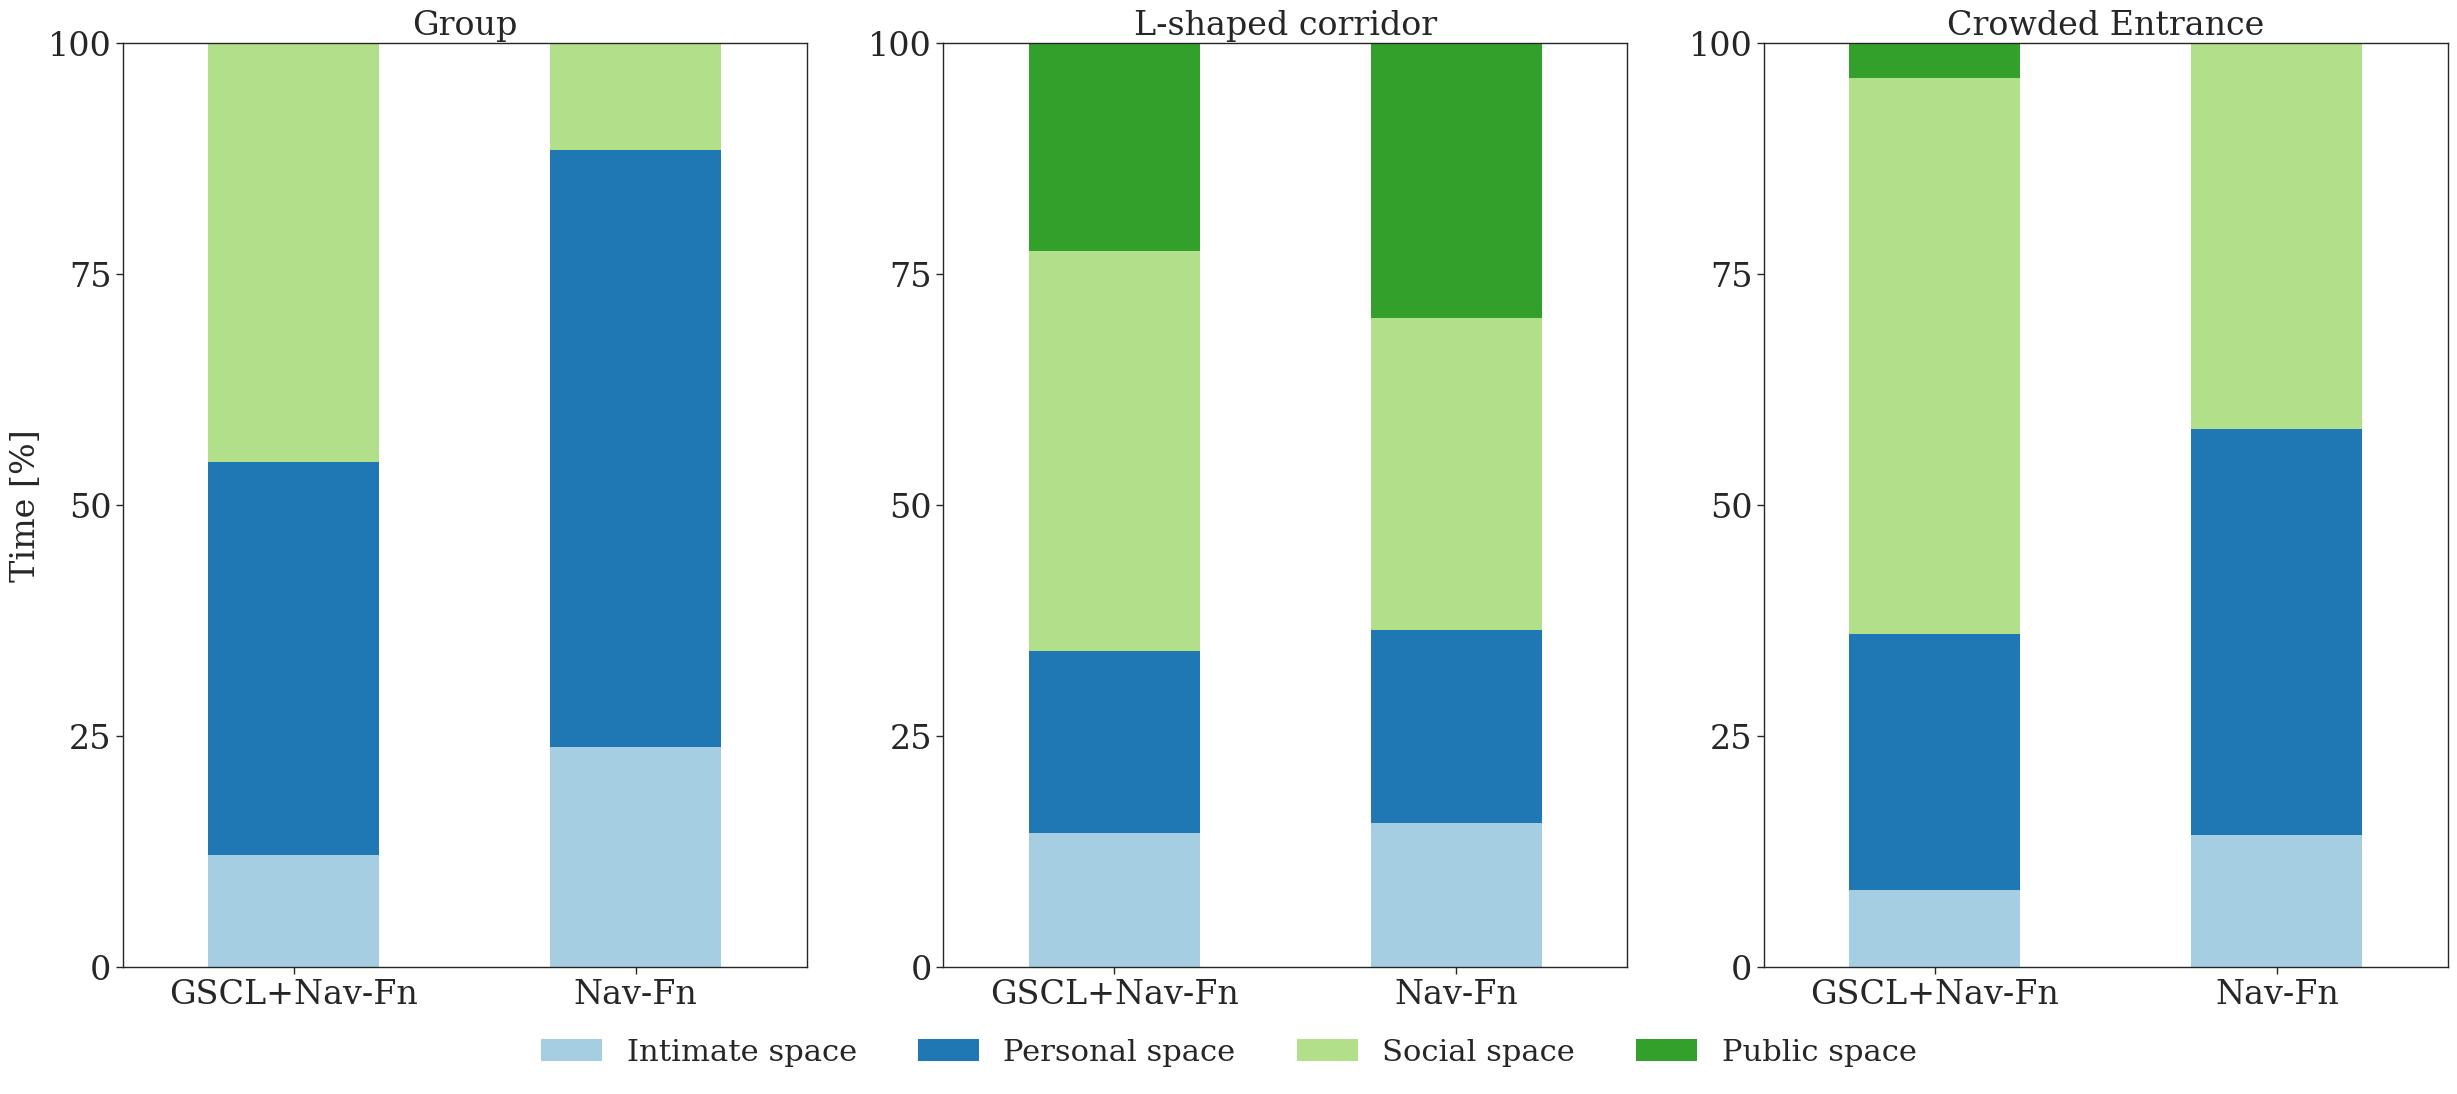

In [44]:
# instogram of the proxemic distances
import matplotlib.pyplot as plt
import seaborn as sns
# sns.set(style="whitegrid")

# print(mean_metrics['experiment'].unique())
# environments = ['group', 'l_shaped_compliant','l_shaped_not_compliant', 'split_with_two_entry_points']
environments = ['group', 'l_shaped_not_compliant', 'split_with_two_entry_points']
algorithm_names = ['GSCL+Nav-Fn', 'Nav-Fn']
environment_names = ['Group', 'L-shaped corridor', 'Crowded Entrance']
episodes_n = len(environments)

#use a style compatible with tikz plots
plt.style.use('seaborn-ticks')
sns.set_context("paper")
# use font roman
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']
# sns.set_context("talk")
# font size


# substitute the algorithm names
mean_metrics['algorithm'] = mean_metrics['algorithm'].replace('first_planner', 'GSCL+Nav-Fn')
mean_metrics['algorithm'] = mean_metrics['algorithm'].replace('second_planner', 'Nav-Fn')
rows = 1
cols = episodes_n // rows
fig, ax = plt.subplots(rows, cols, figsize=(10 * episodes_n, 12))
intrusions = ['intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions']
for i, environment in enumerate(environments):
#   runs_df[runs_df['environment'] == i+1].plot.bar(ax=ax[i//cols, i%cols], x='method', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
#   mean_metrics[mean_metrics['experiment'] == environment].plot.bar(ax=ax[i//cols, i%cols], x='algorithm', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
#   ax[i//cols, i%cols].set_title(environment_names[i], fontsize=22)
#   ax[i//cols, i%cols].legend().remove()
#   ax[i//cols, i%cols].set_ylabel('Time [%]')
#   ax[i//cols, i%cols].set_xlabel('')
#   ax[i//cols, i%cols].set_ylim(0, 100)
#   ax[i//cols, i%cols].set_yticks([0, 25, 50, 75, 100])
    mean_metrics[mean_metrics['experiment'] == environment].plot.bar(ax=ax[i], x='algorithm', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
    ax[i].set_title(environment_names[i], fontsize=22)
    ax[i].legend().remove()
    # ax[i].set_ylabel('Time [%]')
    ax[i].set_xlabel('')
    ax[i].set_ylim(0, 100)
    ax[i].set_yticks([0, 25, 50, 75, 100])
    #set the y label only for the first plot
    if i == 0:
        ax[i].set_ylabel('Time [%]')
    else:
        ax[i].set_ylabel('')

  # modify font size
#   for item in ([ax[i//cols, i%cols].title, ax[i//cols, i%cols].xaxis.label, ax[i//cols, i%cols].yaxis.label] +
#              ax[i//cols, i%cols].get_xticklabels() + ax[i//cols, i%cols].get_yticklabels()):
#     item.set_fontsize(20)
    for item in ([ax[i].title, ax[i].xaxis.label, ax[i].yaxis.label] +
              ax[i].get_xticklabels() + ax[i].get_yticklabels()):
        item.set_fontsize(24)


# from matplotlib.
labels = ['Intimate space', 'Personal space', 'Social space', 'Public space']
fig.legend(labels=labels, loc='lower center', ncol=4, fontsize=22)


fig.savefig('/workspaces/hunavsim_ws/bags/metrics/plot_proxemic_distances.png', bbox_inches='tight')

In [ ]:
std_dev_metrics.round(2)


,experiment,algorithm,path_length_x,path_length_y,minimum_distance_to_people,avg_distance_to_closest_person,maximum_distance_to_people,intimate_space_intrusions,personal_space_intrusions,social_space_intrusions,public_space_intrusions,robot_on_person_collision,person_on_robot_collision,social_force_on_agents,social_force_on_robot,social_work,social_work_per_second,obstacle_force_on_agents,obstacle_force_on_robot,run
0,group,first_planner,1.29,1.29,0.27,0.15,0.38,11.36,5.98,5.53,0.00,0.0,0.0,45.89,45.89,469.06,0.33,7.27,476.98,1.00
1,group,second_planner,3.39,3.39,0.45,0.14,0.20,13.99,13.05,13.25,0.00,0.0,0.0,92.60,92.60,155.89,0.04,3.94,2.40,1.00
2,l_shaped_compliant,first_planner,4.76,4.76,0.17,0.52,1.16,4.75,4.85,33.26,29.85,0.0,0.0,137.83,137.83,2454.95,1.66,330230.47,1962.03,1.00
3,l_shaped_compliant,second_planner,5.30,5.30,0.14,0.06,0.78,2.35,3.26,9.42,4.22,0.0,0.0,51.45,51.45,206.51,0.18,8853090.18,159.71,1.00
4,l_shaped_not_compliant,first_planner,3.35,3.35,0.01,0.50,0.08,3.94,1.55,26.00,20.51,0.0,0.0,23.10,23.10,225.29,0.12,14521.44,299.55,0.71
5,l_shaped_not_compliant,second_planner,6.70,6.70,0.42,0.03,0.08,4.89,0.33,4.06,0.49,0.0,0.0,38.41,38.41,108.55,0.64,205088.97,718.38,0.71
6,split_with_two_entry_points,first_planner,13.48,13.48,0.52,0.36,0.16,13.26,7.94,12.48,3.31,0.0,0.0,262.53,262.53,30975.86,12.35,783001.80,39814.18,1.00
7,split_with_two_entry_points,second_planner,11.82,11.82,0.35,0.12,0.72,13.54,24.93,12.80,0.00,0.0,0.0,99.41,99.41,8265.83,20.65,966530.62,10340.43,1.00
